## Porto Taxi 01 Overall Characterization (Flag 1)

### Dataset Overview
The main table contains completed taxi trips and pickup-channel fields. The trajectory table contains the 15-second GPS points for the same trips.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Analyze the spatial and temporal patterns of taxi driving activity in a selected area during one day.

Role: Urban taxi operations analyst


Category: Taxi service and driving behavior

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trips.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: When does average taxi speed reach local minima during the day?

#### Analysis action

Compare the two low-speed windows before interpreting their spatial correlates.

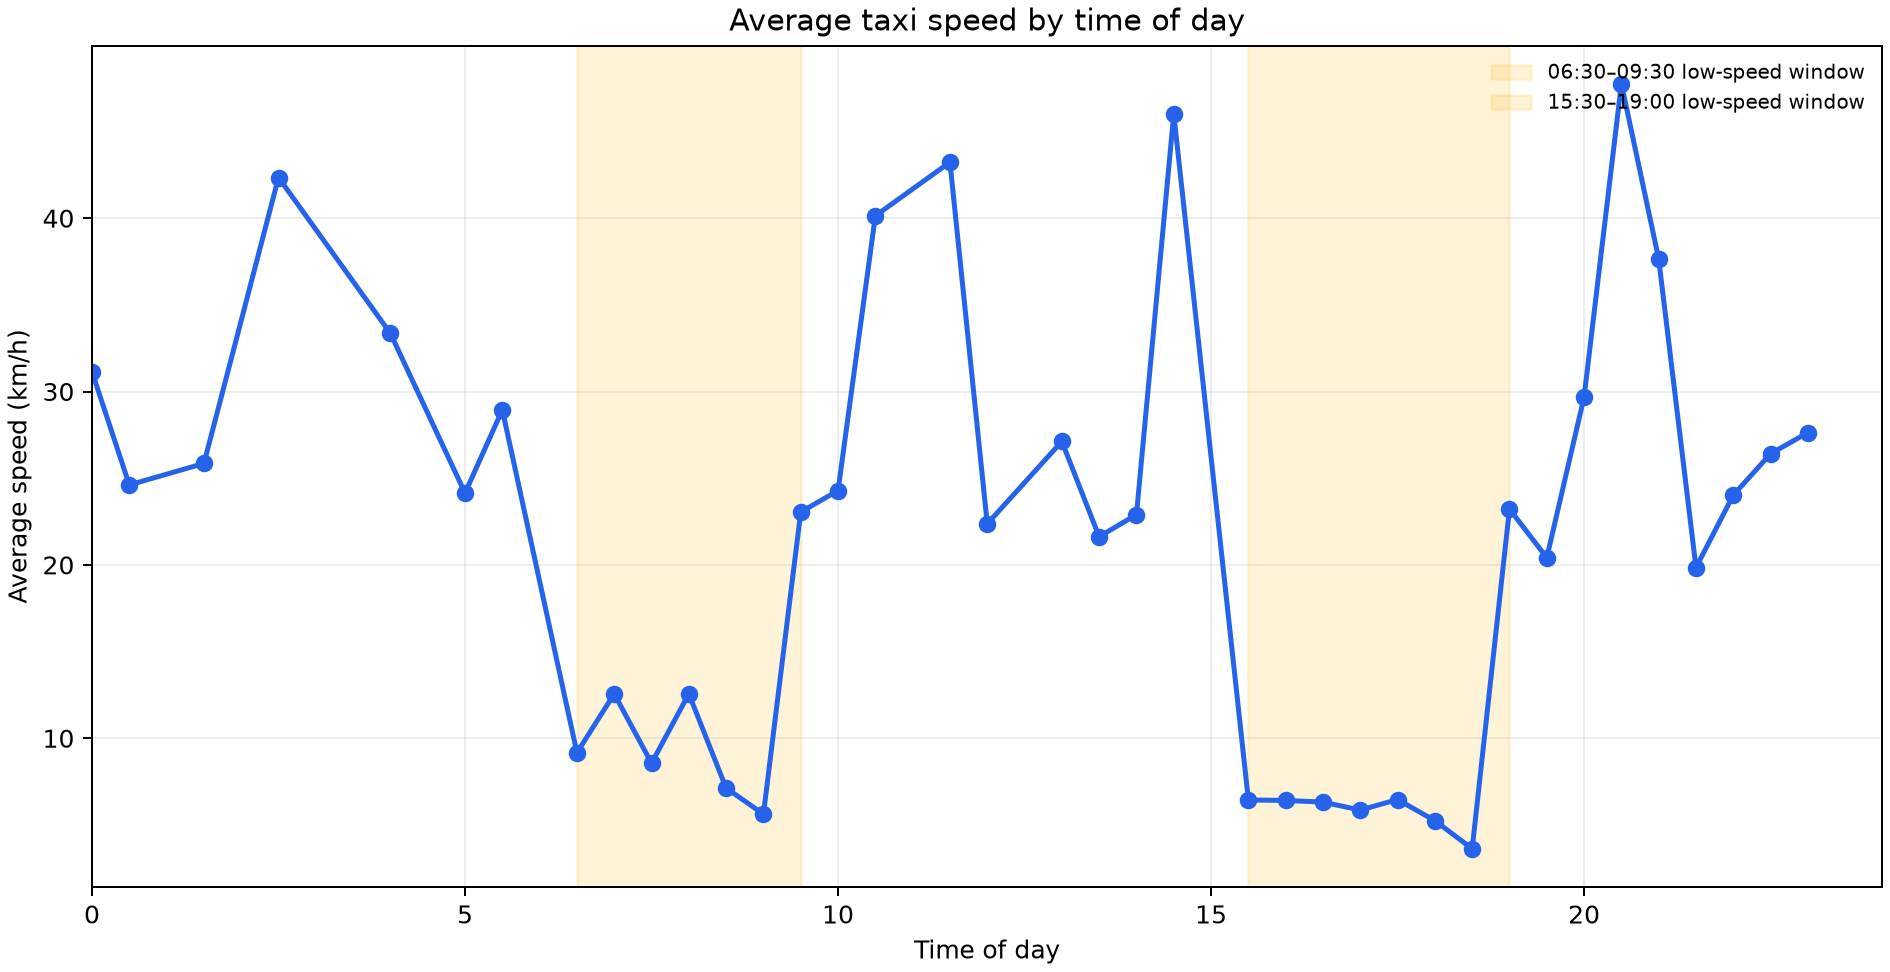

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

d = df.copy()
d['start_time'] = pd.to_datetime(d['timestamp'])
d['speed_kmh'] = d['distance_km'] / d['duration_seconds'].replace(0, pd.NA) * 3600
d['time_bin'] = d['start_time'].dt.floor('30min')
speed = d.groupby('time_bin')['speed_kmh'].mean()
speed.plot(figsize=(12,5), marker='o')
plt.title('Average taxi speed by time of day')
plt.xlabel('Time')
plt.ylabel('Average speed (km/h)')
plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/speed_by_time.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "comparative",
  "insight": "Average taxi speed reaches local minima during 06:30–09:30 and 15:30–19:00.",
  "insight_value": {
    "periods": [
      "06:30–09:30",
      "15:30–19:00"
    ]
  },
  "plot": {
    "plot_type": "line_chart",
    "title": "Average Speed by Time of Day",
    "file": "visualizations/speed_by_time.png",
    "description": "Average taxi speed is plotted in 30-minute bins with the two low-speed windows highlighted."
  },
  "question": "When does average taxi speed reach local minima during the day?",
  "actionable_insight": "Compare the two low-speed windows before interpreting their spatial correlates.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\n\nd = df.copy()\nd['start_time'] = pd.to_datetime(d['timestamp'])\nd['speed_kmh'] = d['distance_km'] / d['duration_seconds'].replace(0, pd.NA) * 3600\nd['time_bin'] = d['start_time'].dt.floor('30min')\nspeed = d.groupby('time_bin')['speed_kmh'].mean()\nspeed.plot(figsize=(12,5), marker='o')\nplt.title('Average taxi speed by time of day')\nplt.xlabel('Time')\nplt.ylabel('Average speed (km/h)')\nplt.show()",
  "insight_type": "temporal_dynamics",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "departure_time",
    "gps_position",
    "trajectory_id"
  ]
}

### **Question 2**: Do most morning trajectories pass through a common junction during the low-speed period?

#### Analysis action

Use the map to compare the common junction with the observed morning routes.

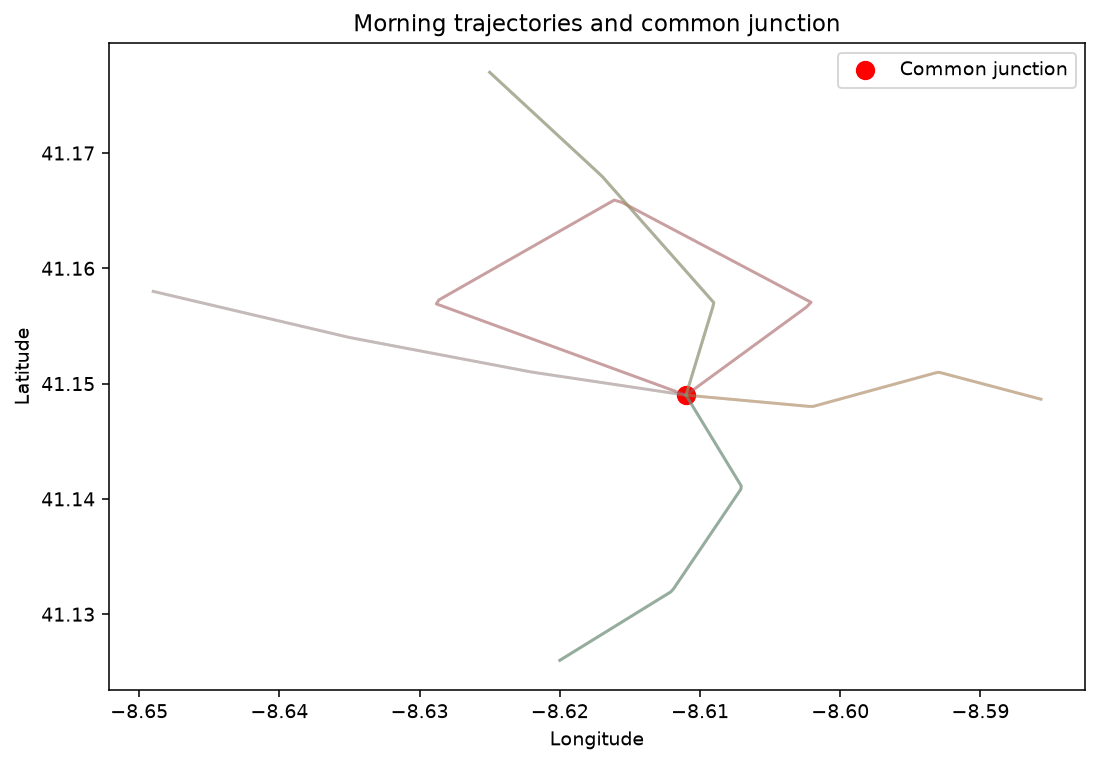

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

t = pd.read_csv('trajstory_examples/insight/Porto_taxi/01_overall_characterization/trajectory_points.csv')
t['timestamp'] = pd.to_datetime(t['timestamp'])
t = t[(t['timestamp'].dt.hour + t['timestamp'].dt.minute / 60 >= 6.5) & (t['timestamp'].dt.hour + t['timestamp'].dt.minute / 60 < 9.5)]
plt.figure(figsize=(9,6))
for _, q in t.groupby('trajectory_id'):
 plt.plot(q['lon'], q['lat'], alpha=.35)
plt.scatter([-8.611], [41.149], c='red', s=80, label='Common junction')
plt.xlabel('Longitude'); plt.ylabel('Latitude'); plt.title('Morning trajectories and common junction')
plt.legend(); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="notebook_plots/q2_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "diagnostic",
  "insight": "During the 06:30–09:30 low-speed period, most taxis in the selected area pass through the same road junction, which is a possible spatial correlate of the low observed speed.",
  "insight_value": {
    "junction": "central Porto junction",
    "period": "06:30–09:30"
  },
  "plot": {
    "plot_type": "map",
    "title": "Morning Trajectories and Common Junction",
    "file": "notebook_plots/q2_1.png",
    "description": "Morning trajectories are overlaid with the common junction marker."
  },
  "question": "Do most morning trajectories pass through a common junction during the low-speed period?",
  "actionable_insight": "Use the map to compare the common junction with the observed morning routes.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\n\nt = pd.read_csv('trajstory_examples/insight/Porto_taxi/01_overall_characterization/trajectory_points.csv')\nt['timestamp'] = pd.to_datetime(t['timestamp'])\nt = t[(t['timestamp'].dt.hour + t['timestamp'].dt.minute / 60 >= 6.5) & (t['timestamp'].dt.hour + t['timestamp'].dt.minute / 60 < 9.5)]\nplt.figure(figsize=(9,6))\nfor _, q in t.groupby('trajectory_id'):\n plt.plot(q['lon'], q['lat'], alpha=.35)\nplt.scatter([-8.611], [41.149], c='red', s=80, label='Common junction')\nplt.xlabel('Longitude'); plt.ylabel('Latitude'); plt.title('Morning trajectories and common junction')\nplt.legend(); plt.show()",
  "insight_type": "factor_relationship",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "departure_time",
    "gps_position",
    "trajectory_id",
    "taxi_id"
  ]
}

### **Question 3**: Do most trips during the afternoon low-speed period start at taxi stands A and B?

#### Analysis action

Use the station-location table and origin-share chart to verify the concentration.

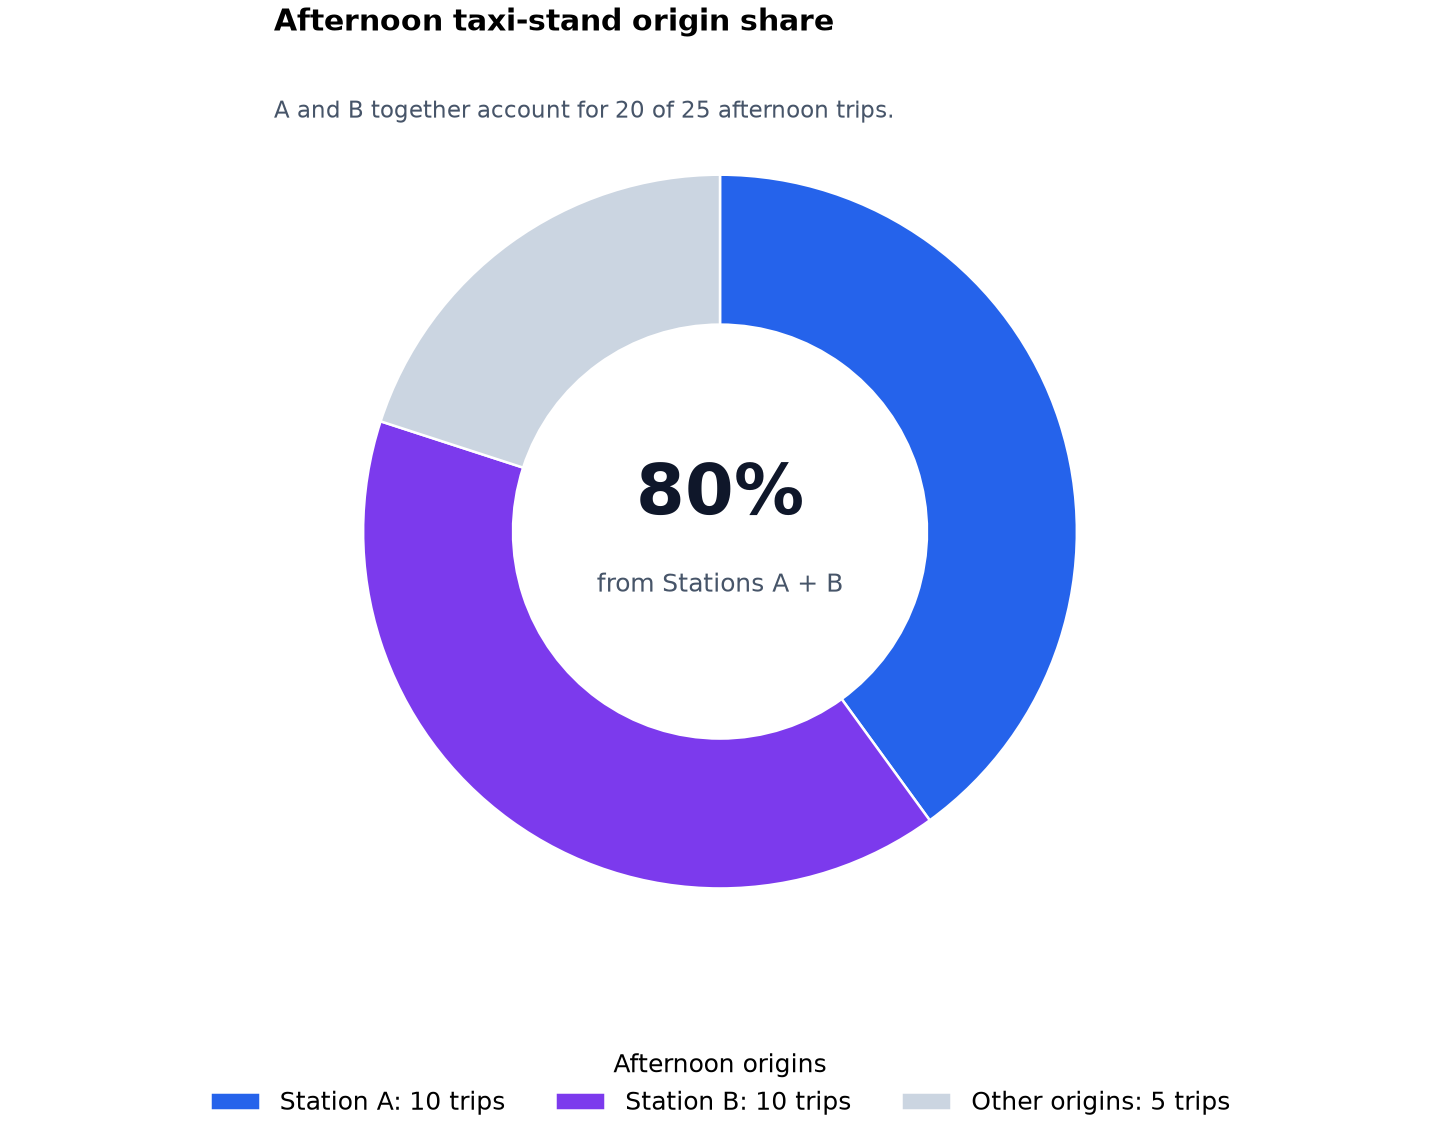

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

d = df.copy(); t = pd.to_datetime(d['timestamp']); h = t.dt.hour + t.dt.minute / 60
d = d[(h >= 15.5) & (h < 19)]
d['station'] = d['origin_stand'].map({'15':'Station A','16':'Station B'}).fillna('Other origins')
d['station'].value_counts().reindex(['Station A','Station B','Other origins']).plot(kind='pie',autopct='%1.0f%%',ylabel='')
plt.title('Afternoon trip-origin share'); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/afternoon_taxi_stand_share.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "descriptive",
  "insight": "During the 15:30-19:00 low-speed period, most trips start at the two taxi-stand locations A and B.",
  "insight_value": {
    "station_share": 0.8,
    "stations": [
      "A",
      "B"
    ]
  },
  "plot": {
    "plot_type": "donut_chart",
    "title": "Afternoon Taxi-Stand Origin Share",
    "file": "visualizations/afternoon_taxi_stand_share.png",
    "description": "The composition separates Station A, Station B, and all other afternoon origins; the center shows their combined share."
  },
  "question": "Do most trips during the afternoon low-speed period start at taxi stands A and B?",
  "actionable_insight": "Use the station-location table and origin-share chart to verify the concentration.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\n\nd = df.copy(); t = pd.to_datetime(d['timestamp']); h = t.dt.hour + t.dt.minute / 60\nd = d[(h >= 15.5) & (h < 19)]\nd['station'] = d['origin_stand'].map({'15':'Station A','16':'Station B'}).fillna('Other origins')\nd['station'].value_counts().reindex(['Station A','Station B','Other origins']).plot(kind='pie',autopct='%1.0f%%',ylabel='')\nplt.title('Afternoon trip-origin share'); plt.show()",
  "insight_type": "overall_pattern",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "departure_time",
    "gps_position",
    "origin_stand",
    "trajectory_id"
  ]
}

### **Question 4**: How are the three CALL_TYPE categories distributed outside the two low-speed periods?

#### Analysis action

Compare the three pickup channels directly across the remaining periods.

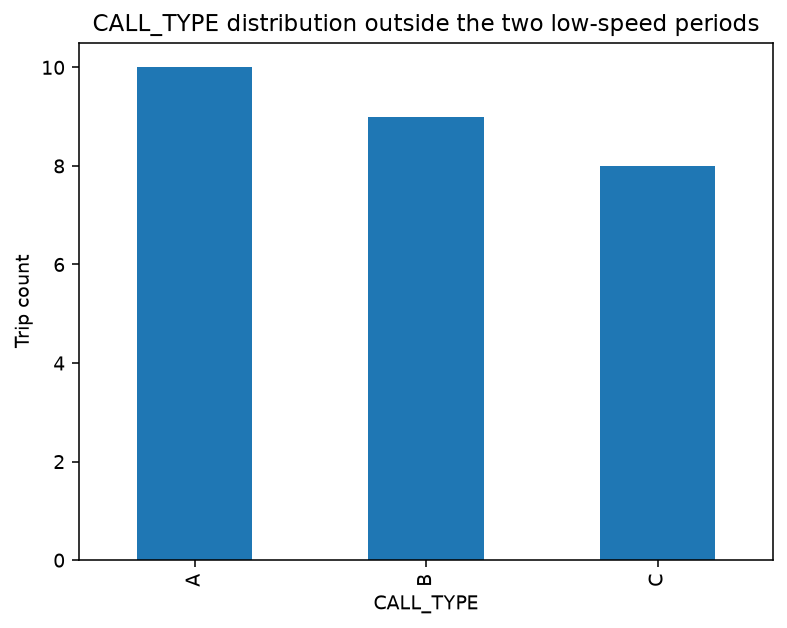

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

d = df.copy()
t = pd.to_datetime(d['timestamp'])
h = t.dt.hour + t.dt.minute / 60
d = d[(h < 6.5) | ((h >= 9.5) & (h < 15.5)) | (h >= 19)]
d['CALL_TYPE'] = d['call_type']
d['CALL_TYPE'].value_counts().reindex(['A','B','C'], fill_value=0).plot(kind='bar')
plt.title('CALL_TYPE distribution outside the two low-speed periods')
plt.xlabel('CALL_TYPE'); plt.ylabel('Trip count'); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="notebook_plots/q4_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "descriptive",
  "insight": "Outside the 06:30–09:30 and 15:30–19:00 periods, the three CALL_TYPE categories are approximately balanced.",
  "insight_value": {
    "period": "outside low-speed windows",
    "categories": [
      "A",
      "B",
      "C"
    ]
  },
  "plot": {
    "plot_type": "bar_chart",
    "title": "CALL_TYPE Distribution Outside Low-Speed Windows",
    "file": "notebook_plots/q4_1.png",
    "description": "The remaining-period counts are close but not identical: CALL_TYPE A=10, B=9, and C=8."
  },
  "question": "How are the three CALL_TYPE categories distributed outside the two low-speed periods?",
  "actionable_insight": "Compare the three pickup channels directly across the remaining periods.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\n\nd = df.copy()\nt = pd.to_datetime(d['timestamp'])\nh = t.dt.hour + t.dt.minute / 60\nd = d[(h < 6.5) | ((h >= 9.5) & (h < 15.5)) | (h >= 19)]\nd['CALL_TYPE'] = d['call_type']\nd['CALL_TYPE'].value_counts().reindex(['A','B','C'], fill_value=0).plot(kind='bar')\nplt.title('CALL_TYPE distribution outside the two low-speed periods')\nplt.xlabel('CALL_TYPE'); plt.ylabel('Trip count'); plt.show()",
  "insight_type": "overall_pattern",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "departure_time",
    "request_source",
    "trajectory_id"
  ]
}

### Summary of Findings (Flag 1)

Taxi driving in the selected Porto area shows two low-speed periods with different spatial contexts: a recurring morning junction and a concentration of afternoon trip origins at two taxi stands. Outside these periods, pickup channels are approximately balanced.